<a id='home'></a>
### Contents

[Imports](#Imports)

[Problem 11](#Problem11)

[Problem 12](#Problem12)

[Problem 14](#Problem14)

<a id='Imports'></a>
### Imports
[back to contents](#home)

In [ ]:
# !pip3 install -q optuna==3.0.2
# !pip3 install optuna

In [19]:
import os
import sys
import time
import itertools
from tqdm.notebook import tqdm
import pickle
import json
import joblib
import collections

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from IPython.display import clear_output

import warnings
warnings.filterwarnings('ignore')

In [20]:
# to display decision tree
from io import StringIO
from IPython.display import Image
from sklearn.tree import export_graphviz
import pydotplus

In [21]:
matplotlib.rcParams['figure.figsize'] = (8, 8)
sns.set_style('whitegrid')

In [ ]:
# # Подключение данных гугл диска
# from google.colab import drive
# drive.mount('/content/drive')

Mounted at /content/drive


### Problem 2

#### Условие

- По выборке на рисунке обучить решающее дерево c критерием деления узлов -- Gini
- Изобразите решающую границу для полученного дерева и визуализируйте дерево в виде иерархической структуры. Проделать то же самое для энтропийного критерия


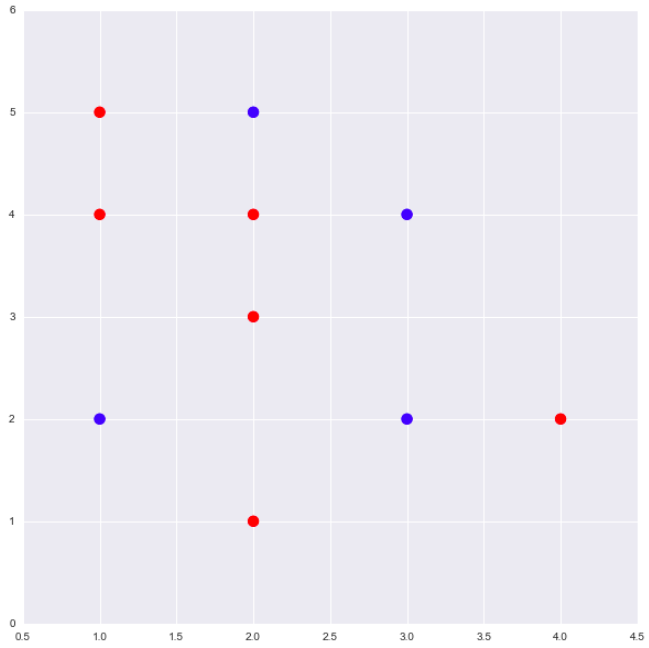

#### Решение

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay

In [23]:
X = np.array([[1, 2], [1, 4], [1, 5], [2, 1], [2, 3], [2, 4], [2, 5], [3, 2], [3, 4], [4, 2]])
y = np.array([0, 1, 1, 1, 1, 1, 0, 0, 0, 1])

In [24]:
tree_gini = DecisionTreeClassifier(criterion='gini', max_depth=None, min_samples_leaf=1, min_samples_split=2)
tree_gini.fit(X, y)

tree_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=None, min_samples_leaf=1, min_samples_split=2)
tree_entropy.fit(X, y)

DecisionTreeClassifier(criterion='entropy')

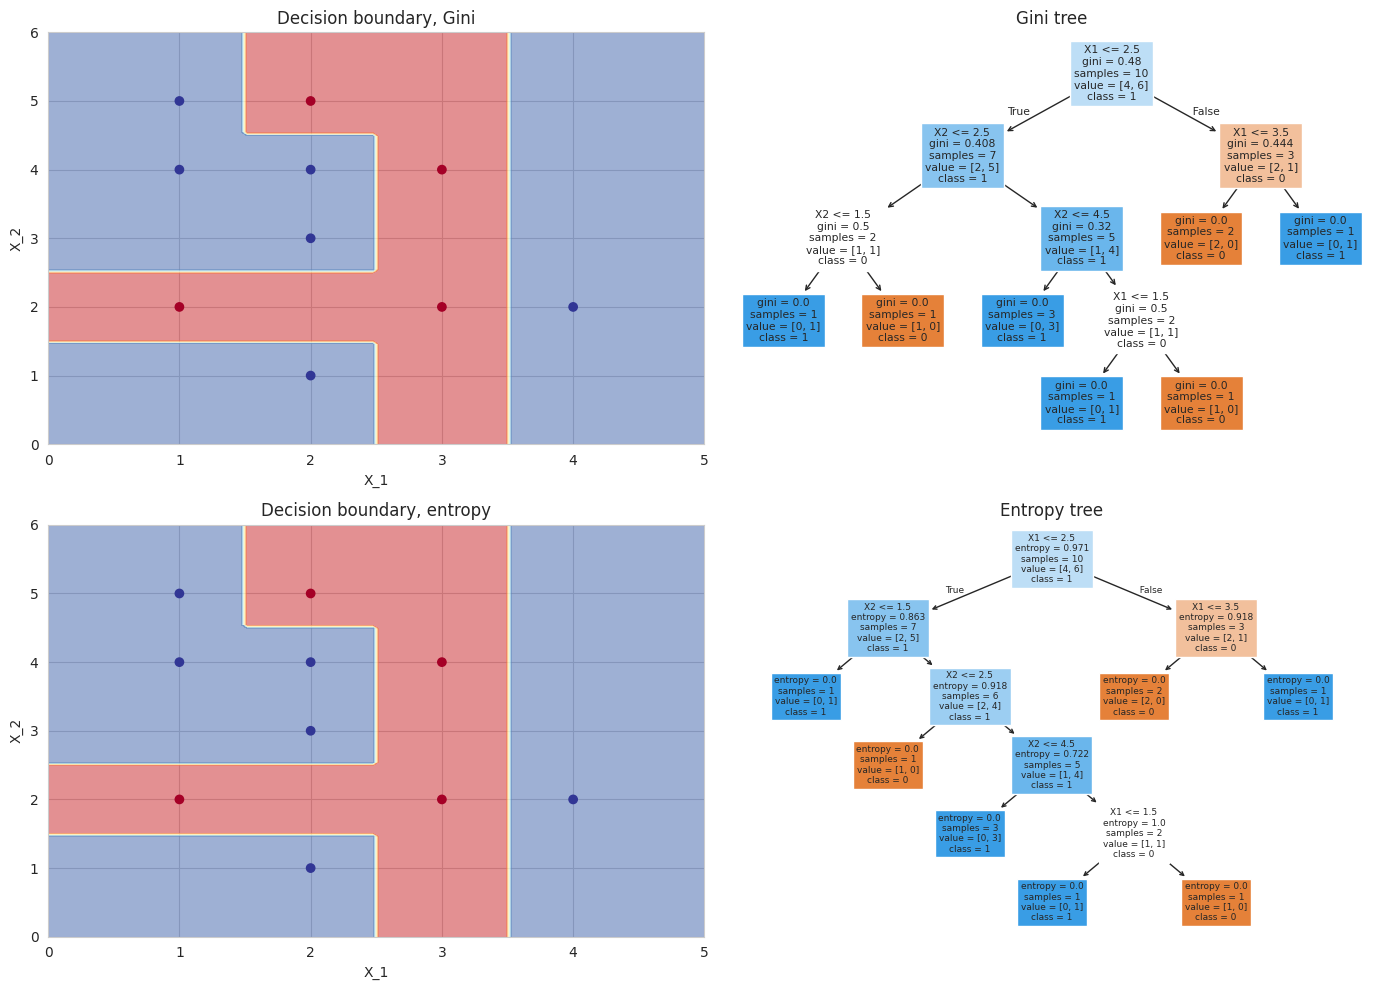

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Gini
viz_gini = DecisionBoundaryDisplay.from_estimator(tree_gini, X, cmap=plt.cm.RdYlBu, alpha=0.5, ax=axes[0, 0])
axes[0, 0].scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu)
axes[0, 0].set_xlabel('X_1')
axes[0, 0].set_ylabel('X_2')
axes[0, 0].set_title('Decision boundary, Gini')
plot_tree(tree_gini, ax=axes[0, 1], class_names=['0', '1'], feature_names=['X1', 'X2'], filled=True, impurity=True, proportion=False)
axes[0, 1].set_title('Gini tree')

# Entropy
viz_entropy = DecisionBoundaryDisplay.from_estimator(tree_entropy, X, cmap=plt.cm.RdYlBu, alpha=0.5, ax=axes[1, 0])
axes[1, 0].scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu)
axes[1, 0].set_xlabel('X_1')
axes[1, 0].set_ylabel('X_2')
axes[1, 0].set_title('Decision boundary, entropy')
plot_tree(tree_entropy, ax=axes[1, 1], class_names=['0', '1'], feature_names=['X1', 'X2'], filled=True, impurity=True, proportion=False)
axes[1, 1].set_title('Entropy tree')

plt.tight_layout()
plt.show()

In [26]:
print("Критерий Gini")
print(export_text(tree_gini, feature_names=['X1', 'X2']))

Критерий Gini
|--- X1 <= 2.50
|   |--- X2 <= 2.50
|   |   |--- X2 <= 1.50
|   |   |   |--- class: 1
|   |   |--- X2 >  1.50
|   |   |   |--- class: 0
|   |--- X2 >  2.50
|   |   |--- X2 <= 4.50
|   |   |   |--- class: 1
|   |   |--- X2 >  4.50
|   |   |   |--- X1 <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- X1 >  1.50
|   |   |   |   |--- class: 0
|--- X1 >  2.50
|   |--- X1 <= 3.50
|   |   |--- class: 0
|   |--- X1 >  3.50
|   |   |--- class: 1



#### gini, entropy и missclassification

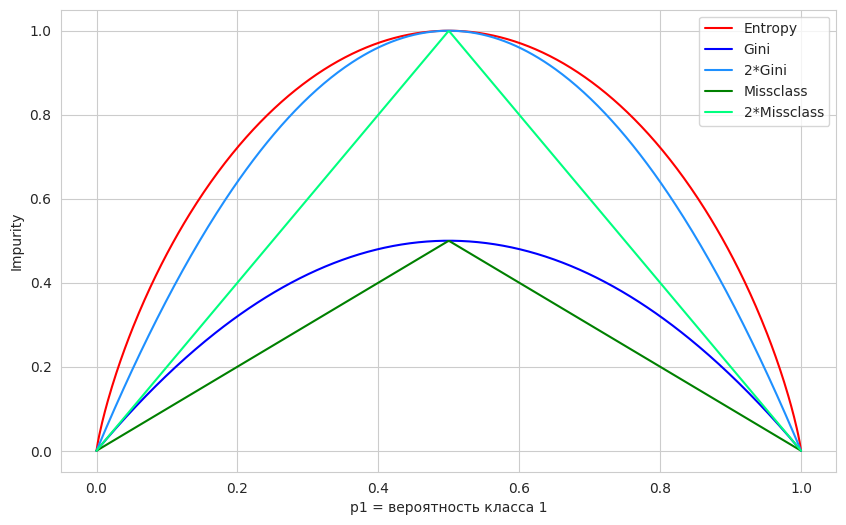

In [27]:
def gini_impurity(p):
    return 2*p*(1-p)

def entropy_impurity(p):
    return -np.where(p==0, 0, p*np.log2(p)) - np.where(p==1, 0, (1-p)*np.log2(1-p))

def missclass_impurity(p):
    return 1-np.maximum(p, 1-p)

p_values = np.linspace(0, 1, 500)

gini_values = gini_impurity(p_values)
gini_double_values = 2*gini_values
entropy_values = entropy_impurity(p_values)
missclass_values = missclass_impurity(p_values)
missclass_double_values = 2*missclass_values

plt.figure(figsize=(10, 6))
plt.plot(p_values, entropy_values, label='Entropy', color='red')
plt.plot(p_values, gini_values, label='Gini', color='blue')
plt.plot(p_values, gini_double_values, label='2*Gini', color='dodgerblue')
plt.plot(p_values, missclass_values, label='Missclass', color='green')
plt.plot(p_values, missclass_double_values, label='2*Missclass', color='springgreen')

plt.xlabel('p1 = вероятность класса 1')
plt.ylabel('Impurity')
plt.legend()
plt.grid(True)
plt.show()

#### `.predict()` и `.predict_proba()`

In [11]:
new_points = np.array([[1, 1], [2, 2], [10, 10]])

print(tree_gini.predict(new_points)) # предсказываем метку класса
print(tree_gini.predict_proba(new_points)) # для каждой точки предсказываем вер-ть каждого из классов

[0 1 1]
[[1. 0.]
 [0. 1.]
 [0. 1.]]


#### KNN

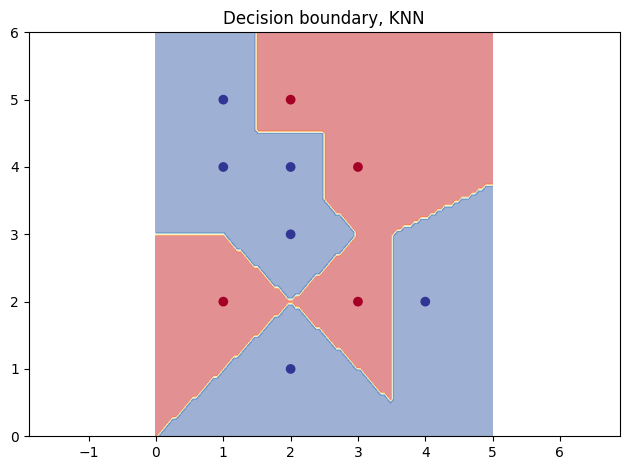

In [ ]:
# KNN
knn = KNeighborsClassifier(n_neighbors=1, metric='minkowski', p=2, weights='uniform')
knn.fit(X, y)
viz_knn = DecisionBoundaryDisplay.from_estimator(knn, X, cmap=plt.cm.RdYlBu, alpha=0.5)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu)
plt.title('Decision boundary, KNN')
plt.axis('equal')
plt.tight_layout()
plt.show()

#### Регрессия с помощью деревьев

In [28]:
np.random.seed(42)
X = np.sort(5*np.random.rand(80, 1), axis=0) # x от 0 до 5
y = np.sin(X).ravel() + np.random.normal(0, 0.1, X.shape[0]) # y = sin(x) + шум

In [50]:
tree_reg = DecisionTreeRegressor(max_depth=2, min_samples_leaf=2, min_samples_split=2)
tree_reg.fit(X, y)

DecisionTreeRegressor(max_depth=2, min_samples_leaf=2, min_samples_split=10)

In [51]:
X_test = np.arange(0.0, 5.0, 0.01)[:, np.newaxis] # точки от 0 до 5
y_pred = tree_reg.predict(X_test)

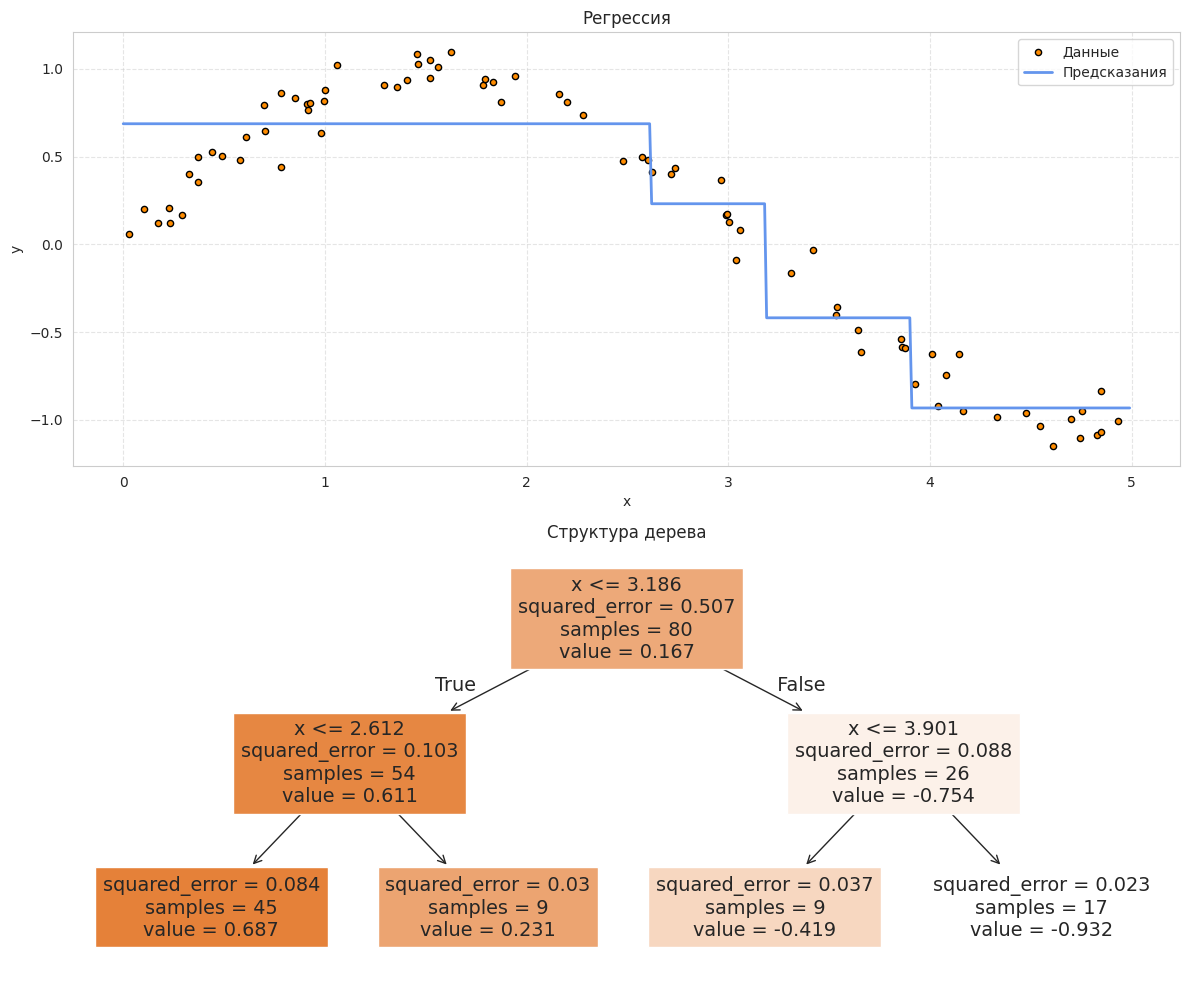

In [52]:
plt.figure(figsize=(12, 10))

plt.subplot(2, 1, 1)
plt.scatter(X, y, s=20, edgecolor="black", c="darkorange", label="Данные")
plt.plot(X_test, y_pred, color="cornflowerblue", label="Предсказания", linewidth=2)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Регрессия")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(2, 1, 2)
plot_tree(tree_reg, feature_names=["x"], filled=True, impurity=True, proportion=False)
plt.title("Структура дерева")

plt.tight_layout()
plt.show()

### Problem 8

Для проблемы [XOR](https://en.wikipedia.org/wiki/Exclusive_or) постройте решающее дерево и посчитайте важности признаков.

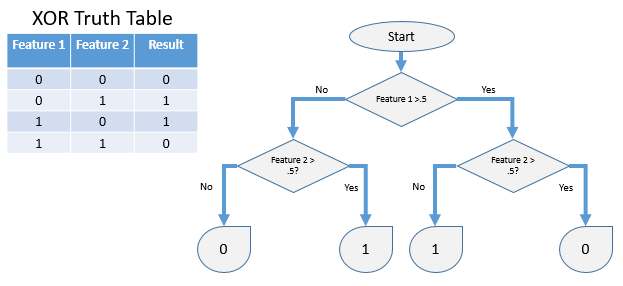

In [ ]:
from io import StringIO
from IPython.display import Image
from sklearn.tree import export_graphviz
import pydotplus

In [ ]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 1, 1, 0])

clf = DecisionTreeClassifier(criterion='entropy', max_depth=2, random_state=42)
clf.fit(X, y)
print(clf.feature_importances_)

[0. 1.]


In [ ]:
export_graphviz(clf)

'digraph Tree {\nnode [shape=box, fontname="helvetica"] ;\nedge [fontname="helvetica"] ;\n0 [label="x[0] <= 0.5\\nentropy = 1.0\\nsamples = 4\\nvalue = [2, 2]"] ;\n1 [label="x[1] <= 0.5\\nentropy = 1.0\\nsamples = 2\\nvalue = [1, 1]"] ;\n0 -> 1 [labeldistance=2.5, labelangle=45, headlabel="True"] ;\n2 [label="entropy = 0.0\\nsamples = 1\\nvalue = [1, 0]"] ;\n1 -> 2 ;\n3 [label="entropy = 0.0\\nsamples = 1\\nvalue = [0, 1]"] ;\n1 -> 3 ;\n4 [label="x[1] <= 0.5\\nentropy = 1.0\\nsamples = 2\\nvalue = [1, 1]"] ;\n0 -> 4 [labeldistance=2.5, labelangle=-45, headlabel="False"] ;\n5 [label="entropy = 0.0\\nsamples = 1\\nvalue = [0, 1]"] ;\n4 -> 5 ;\n6 [label="entropy = 0.0\\nsamples = 1\\nvalue = [1, 0]"] ;\n4 -> 6 ;\n}'

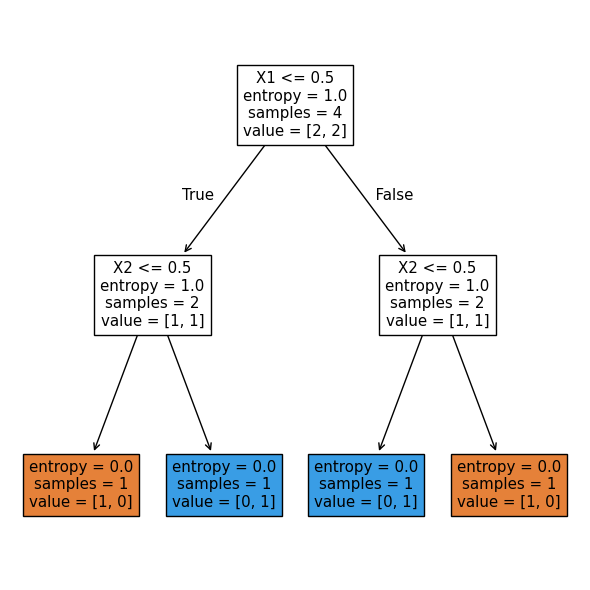

In [ ]:
plt.figure(figsize=(6, 6))
plot_tree(clf, feature_names=["X1", "X2"], filled=True, impurity=True, proportion=False)
plt.tight_layout()
plt.show()

In [ ]:
tree_reg.feature_importances_

array([1.])

### Ансамбли

In [53]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X, y = make_classification(n_samples=1000, n_features=20, n_informative=15, n_redundant=5, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

#### Bagging = (Bootstrap + Aggregation)

- генерируем много подвыборок с возвращением (бутстрап)
- обучаем отдельную модель на каждой подвыборке
- усредняем прогнозы

In [54]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

base_tree = DecisionTreeClassifier(random_state=42)

bagging = BaggingClassifier(
    estimator=base_tree,
    n_estimators=100,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

bagging.fit(X_train, y_train)
y_pred_bag = bagging.predict(X_test)
print(f"Bagging accuracy: {accuracy_score(y_test, y_pred_bag):.3f}")

Bagging accuracy: 0.883


#### Random Forest

- в отличие от бэггинга, выбираем случайное подмножество признаков

In [55]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print(f"Random Forest accuracy: {accuracy_score(y_test, y_pred_rf):.3f}")

Random Forest accuracy: 0.887


#### Extra Trees

- без бутстрапа, обучаемся на исходной выборке
- вместо оптимального расщепления, выбираем набор случайных расщеплений и затем берём лучший из них

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier

et = ExtraTreesClassifier(
    n_estimators=100,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

et.fit(X_train, y_train)
y_pred_et = et.predict(X_test)
print(f"Extra Trees accuracy: {accuracy_score(y_test, y_pred_et):.3f}")

Extra Trees accuracy: 0.930


<a id='Problem12'></a>
### Problem 12
[back to contents](#home)

Написать код, который для данного вектора фичей и вектора таргетов
возвращает список из gain’ов при расщеплении листа по данной фиче при
всех порогах. Протестируйте ваш код на наборе данных: [students.csv](https://drive.google.com/file/d/1bZMmnsJpDETdVtZQXFLu_gjhJZLPk2ey/view?usp=sharing) (целевая
переменная: UNS)

In [ ]:
!gdown https://drive.google.com/uc?id=1-le043ushK2jtV-8J2cg_IYatznP8E06

Downloading...
From: https://drive.google.com/uc?id=1-le043ushK2jtV-8J2cg_IYatznP8E06
To: /content/students.csv
100% 7.25k/7.25k [00:00<00:00, 22.6MB/s]


In [ ]:
import itertools
import pandas as pd
import seaborn as sns
from IPython.display import clear_output

import warnings
warnings.filterwarnings('ignore')

In [ ]:
data = pd.read_csv('/content/students.csv')
data.columns = [col.strip().lower() for col in data.columns]
print(f"{data.shape[0]:,} x {data.shape[1]:,}")
data.head()

258 x 6


,stg,scg,str,lpr,peg,uns
0,0.00,0.00,0.00,0.00,0.00,0
1,0.08,0.08,0.10,0.24,0.90,1
2,0.06,0.06,0.05,0.25,0.33,0
3,0.10,0.10,0.15,0.65,0.30,1
4,0.08,0.08,0.08,0.98,0.24,0


- **STG**: The degree of study time for goal object materails

- **SCG**: The degree of repetition number of user for goal object materials

- **STR**: The degree of study time of user for related objects with goal object

- **LPR**: The exam performance of user for related objects with goal object

- **PEG**: The exam performance of user for goal objects

- **UNS**: The knowledge level of user

In [ ]:
target = data['uns']
X = data.drop(['uns'], axis=1)

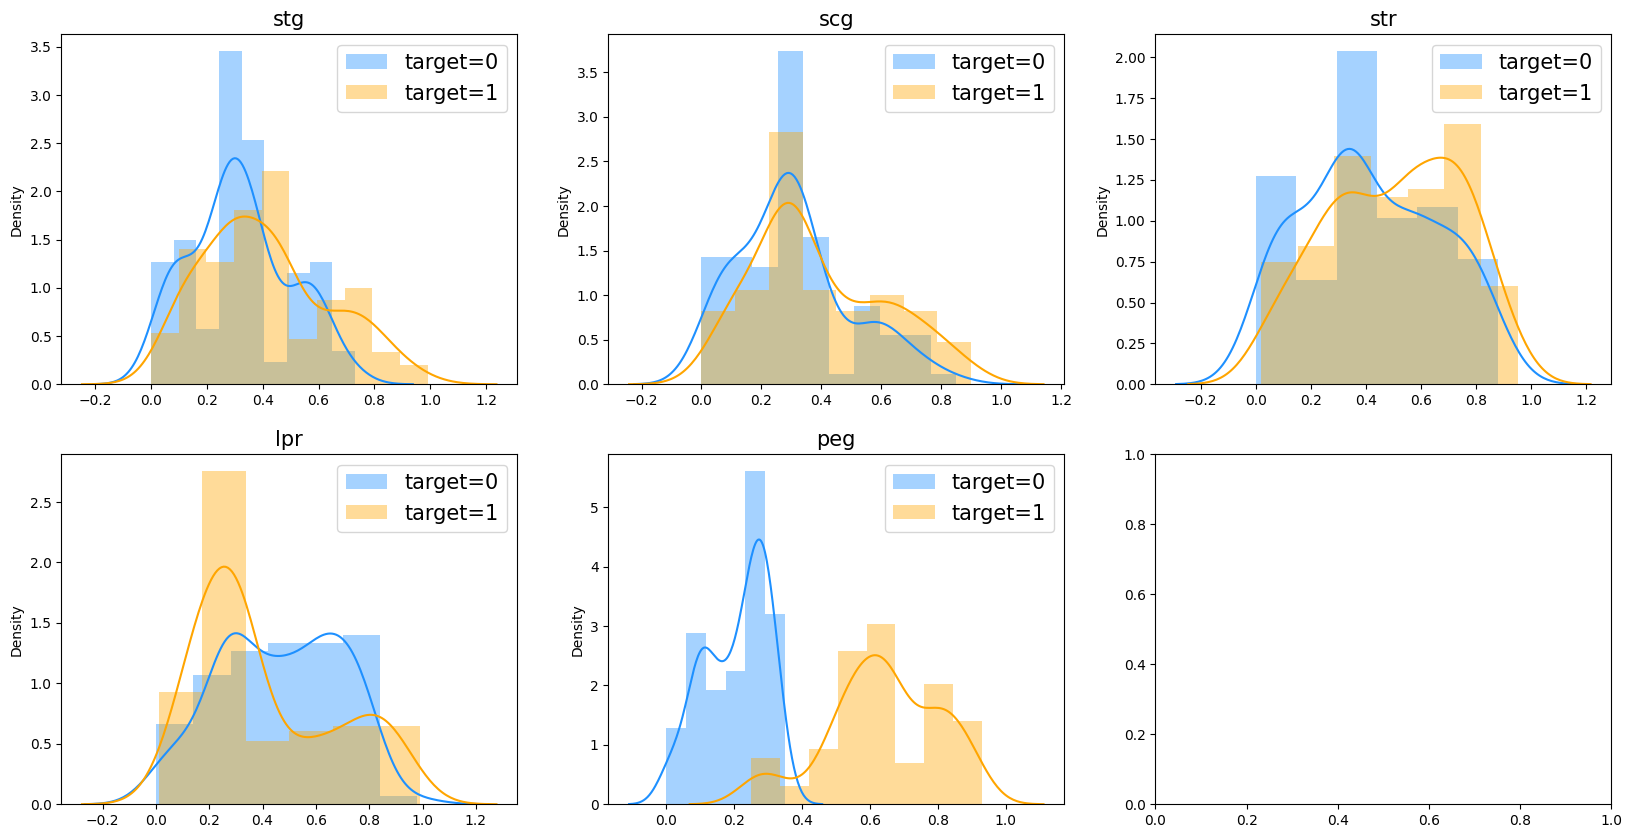

In [ ]:
ncols = 3
nrows = X.shape[1] // ncols if X.shape[1] % ncols == 0 else X.shape[1] // ncols + 1

fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 10))

for i, (row, col) in enumerate(itertools.product(range(nrows), range(ncols))):
  if i == X.shape[1]:
    break

  column = X.columns[i]
  ax[row, col].set_title(column, fontsize=15);
  sns.distplot(X[column][(target == 0)].values, color='dodgerblue', label='target=0', ax=ax[row, col])
  sns.distplot(X[column][(target == 1)].values, color='orange', label='target=1', ax=ax[row, col])
  ax[row, col].legend(fontsize=15);

In [ ]:
import numpy as np

def compute_impurity(target_vector: np.ndarray, criterion: str='gini') -> float:

  """
  Computes impurity of particular leaf
  Args:
    target_vector: target vector for objects in this leaf
    criterion:
      entropy: sum(-p*log2p)
      gini: sum(p*(1-p))
  Returns:
    impurity (gini or entropy)
  """

  assert criterion in ['gini', 'entropy'], 'critetion could be "gini" or "entropy" as for now!'

  unq_classes, counts = np.unique(target_vector, return_counts=True)
  probas_vector = counts / counts.sum()

  if criterion == 'gini':
    return probas_vector @ (1 - probas_vector)
  elif criterion == 'entropy':
    return - probas_vector[probas_vector > 0] @ np.log2(probas_vector[probas_vector > 0])
  else:
    raise ValueError('critetion could be "gini" or "entropy" as for now!')


def compute_gain(target_vector: np.ndarray, feature_vector: np.ndarray, threshold: float, criterion: str='gini') -> float:

  """
  Computes gain of particular leaf split (H_R - |Rl|/|R| * H_Rl - |Rr|/|R| * H_Rr)
  """

  assert criterion in ['gini', 'entropy'], 'critetion could be "gini" or "entropy" as for now!'

  n = len(target_vector)
  n_left = sum(feature_vector < threshold)
  n_right = sum(feature_vector >= threshold)
  H_R = compute_impurity(target_vector=target_vector, criterion=criterion)
  H_Rl = compute_impurity(target_vector=target_vector[feature_vector < threshold], criterion=criterion)
  H_Rr = compute_impurity(target_vector=target_vector[feature_vector >= threshold], criterion=criterion)

  Q = H_R - (n_left/n)*H_Rl - (n_right/n)*H_Rr
  return Q

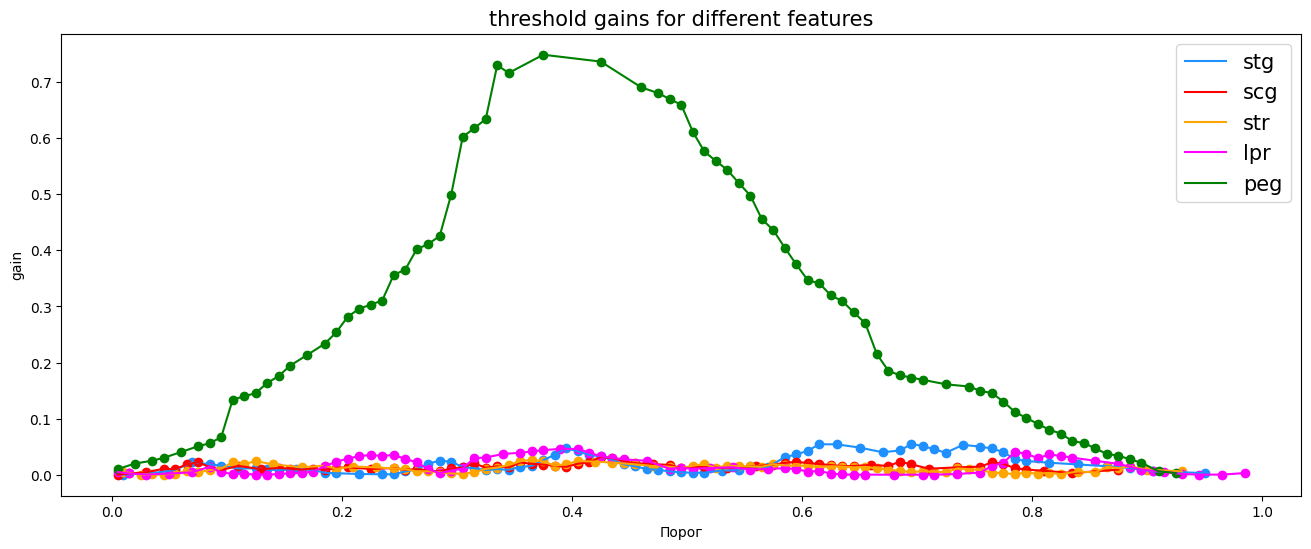

In [ ]:
colors = np.array(['dodgerblue', 'red', 'orange', 'magenta', 'green', 'yellow', 'brown'])

plt.figure(figsize=(16, 6))
plt.title(f'threshold gains for different features', fontsize=15);
for i, col in enumerate(X.columns):
  unq_vals = np.sort(np.unique(X[col]))
  thresholds = (unq_vals[1:] + unq_vals[:-1]) / 2
  gain_vals = np.array([compute_gain(target_vector=target, feature_vector=X[col].values, threshold=t, criterion='entropy') for t in thresholds])
  plt.plot(thresholds, gain_vals, color=colors[i], label=col)
  plt.scatter(thresholds, gain_vals, color=colors[i])

plt.xlabel('Порог')
plt.ylabel('gain')
plt.legend(fontsize=15);

<a id='Problem11'></a>
### Problem 11
[back to contents](#home)

Обучить решающее дерево на [cholesterol_prediction.csv](https://drive.google.com/file/d/1vhcrknQ5oSRizxQK4fS_PxOeS11Fql6Q/view?usp=sharing). В качестве
целевой переменной рассмотрите "cardio".

In [ ]:
!gdown https://drive.google.com/uc?id=1u79RsjQ7BfVyGWoZsTtybkDdlbNHM9mz

Downloading...
From: https://drive.google.com/uc?id=1u79RsjQ7BfVyGWoZsTtybkDdlbNHM9mz
To: /content/cholesterol_prediction.csv
100% 2.94M/2.94M [00:00<00:00, 195MB/s]


In [ ]:
data = pd.read_csv('/content/cholesterol_prediction.csv', sep=';')
data.drop(['id'], axis=1, inplace=True)
print(f"{data.shape[0]:,} x {data.shape[1]:,}")
data.head()

70,000 x 12


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [ ]:
from sklearn.model_selection import train_test_split

X_tr, X_te = train_test_split(data, test_size=0.3, random_state=42, shuffle=True)
y_tr = X_tr['cardio']
del X_tr['cardio']

y_te = X_te['cardio']
del X_te['cardio']

print(f"y_tr: {y_tr.shape[0]:,}")
print(f"\t0: {sum(y_tr == 0):,} ({round(sum(y_tr == 0)*100/len(y_tr), 2)}%)")
print(f"\t1: {sum(y_tr == 1):,} ({round(sum(y_tr == 1)*100/len(y_tr), 2)}%)")
print()
print(f"y_te: {y_te.shape[0]:,}")
print(f"\t0: {sum(y_te == 0):,} ({round(sum(y_te == 0)*100/len(y_te), 2)}%)")
print(f"\t1: {sum(y_te == 1):,} ({round(sum(y_te == 1)*100/len(y_te), 2)}%)")

y_tr: 49,000
	0: 24,560 (50.12%)
	1: 24,440 (49.88%)

y_te: 21,000
	0: 10,461 (49.81%)
	1: 10,539 (50.19%)


In [ ]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(max_depth=None)
model.fit(X_tr, y_tr)

DecisionTreeClassifier()

In [ ]:
from sklearn.metrics import accuracy_score

In [ ]:
train_acc = accuracy_score(
    y_true=y_tr,
    y_pred=model.predict(X_tr)
)
test_acc = accuracy_score(
    y_true=y_te,
    y_pred=model.predict(X_te)
)
print(f"train accuracy: {round(train_acc, 3)}")
print(f"test accuracy: {round(test_acc, 3)}") #overfitting

train accuracy: 1.0
test accuracy: 0.636


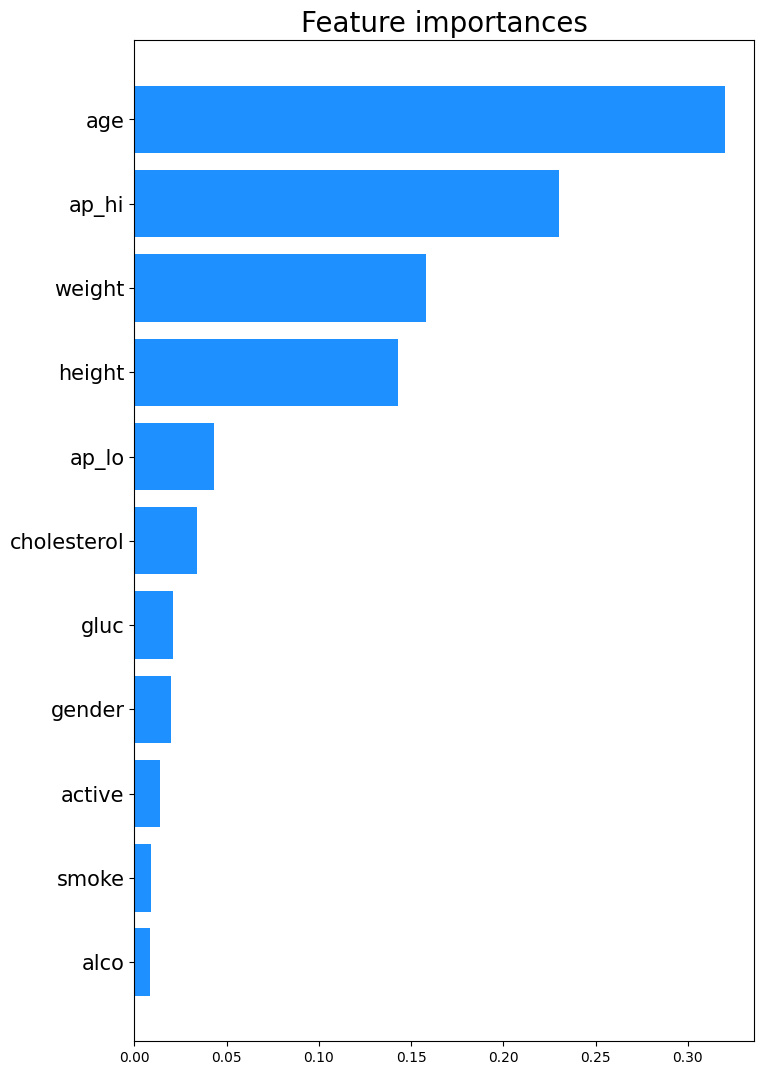

In [ ]:
fn, fi = (
    model.feature_names_in_,
    model.feature_importances_
)
fn = np.array(fn)[np.argsort(fi)][::-1]
fi = np.sort(fi)[::-1]

plt.figure(figsize=(8, 13))
plt.title(f'Feature importances', fontsize=20);
plt.barh(fn[::-1], fi[::-1], color='dodgerblue');
plt.tick_params(axis='y', labelsize=15);

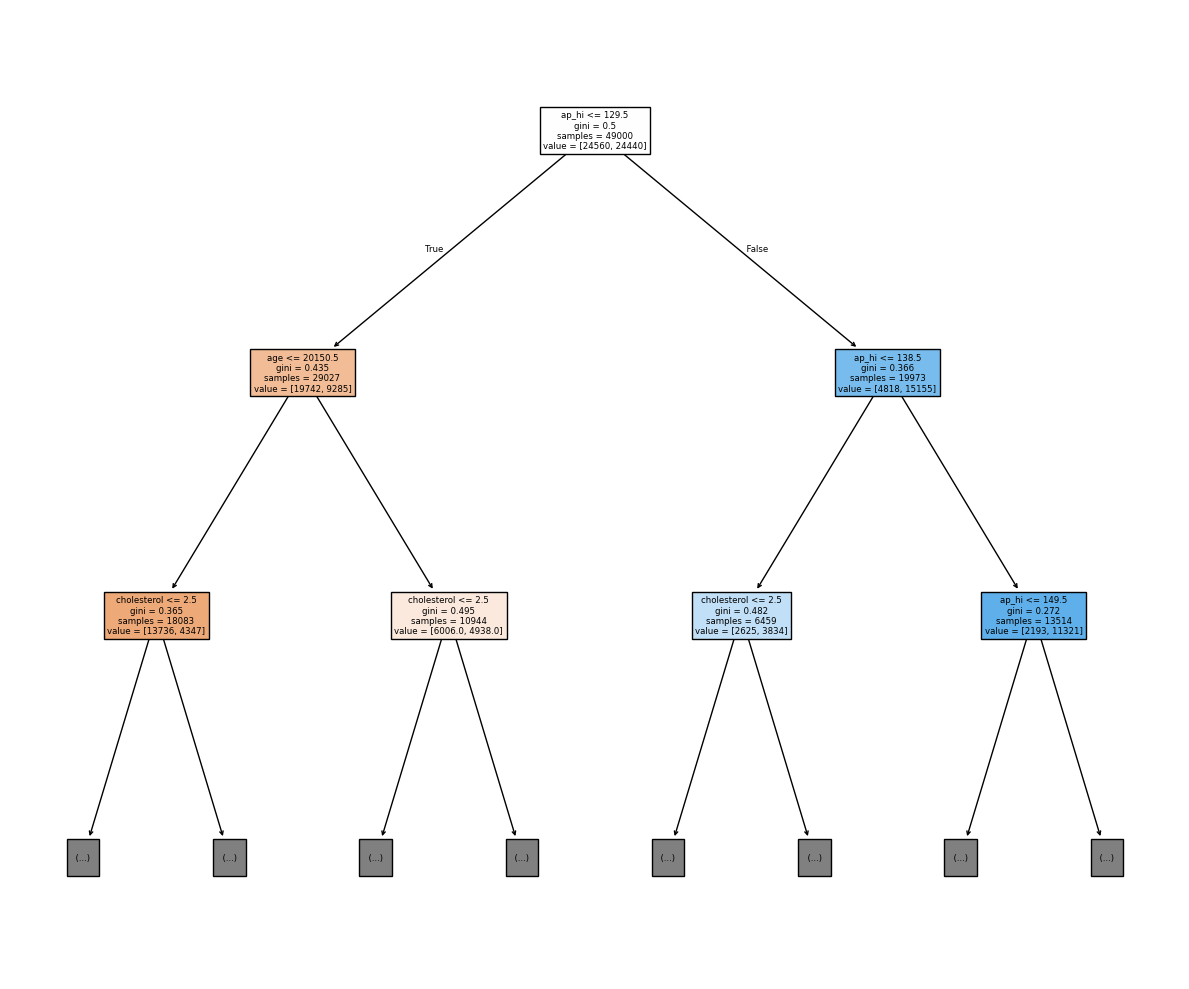

In [ ]:
# only do in case of not deep tree!
# dot_data = StringIO()
# export_graphviz(model, out_file=dot_data,
#                 filled=True, rounded=True,
#                 special_characters=True)
# graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
# Image(graph.create_png())
plt.figure(figsize=(12, 10))
plot_tree(model, max_depth=2, feature_names=model.feature_names_in_, filled=True, impurity=True, proportion=False)
plt.tight_layout()
plt.show()

In [ ]:
!pip3 install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.9/400.9 kB 14.8 MB/s eta 0:00:00


In [ ]:
import optuna
from optuna import trial
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import accuracy_score
from IPython.display import clear_output

In [ ]:
def objective(trial):
    params = {
        "criterion": trial.suggest_categorical('criterion', ['gini', 'entropy']),
        "splitter": "best",
        "max_depth": trial.suggest_int("max_depth", 1, 56),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 200),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 500),
        "max_features": None,
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 5, 20_000, log=True),
        "min_impurity_decrease": trial.suggest_float("min_impurity_decrease", 0, 20)
    }
    model = DecisionTreeClassifier(**params)

    score = cross_val_score(
        estimator=model,
        X=X_tr,
        y=y_tr,
        scoring='accuracy',
        cv=KFold(n_splits=5, shuffle=True),
        n_jobs=-1,
        verbose=0
    )
    accuracy = np.mean(score)
    return accuracy

In [ ]:
%%time
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=100)
clear_output()
best_params = study.best_params
print("best trial:")
print(study.best_trial, end='\n'*2)
print("best params:")
print(best_params, end='\n'*2)

best trial:
FrozenTrial(number=94, state=1, values=[0.7128775510204082], datetime_start=datetime.datetime(2025, 9, 27, 9, 51, 54, 712887), datetime_complete=datetime.datetime(2025, 9, 27, 9, 51, 55, 160695), params={'criterion': 'entropy', 'max_depth': 18, 'min_samples_split': 14, 'min_samples_leaf': 345, 'max_leaf_nodes': 925, 'min_impurity_decrease': 0.005469139410789499}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'criterion': CategoricalDistribution(choices=('gini', 'entropy')), 'max_depth': IntDistribution(high=56, log=False, low=1, step=1), 'min_samples_split': IntDistribution(high=200, log=False, low=2, step=1), 'min_samples_leaf': IntDistribution(high=500, log=False, low=1, step=1), 'max_leaf_nodes': IntDistribution(high=20000, log=True, low=5, step=1), 'min_impurity_decrease': FloatDistribution(high=20.0, log=False, low=0.0, step=None)}, trial_id=94, value=None)

best params:
{'criterion': 'entropy', 'max_depth': 18, 'min_samples_split': 14, 'min_sa

In [ ]:
best_model = DecisionTreeClassifier(**best_params)
best_model.fit(X_tr, y_tr)

DecisionTreeClassifier(criterion='entropy', max_depth=18, max_leaf_nodes=925,
                       min_impurity_decrease=0.005469139410789499,
                       min_samples_leaf=345, min_samples_split=14)

In [ ]:
train_acc = accuracy_score(
    y_true=y_tr,
    y_pred=best_model.predict(X_tr)
)
test_acc = accuracy_score(
    y_true=y_te,
    y_pred=best_model.predict(X_te)
)
print(f"train accuracy: {round(train_acc, 3)}")
print(f"test accuracy: {round(test_acc, 3)}") #overfitting

train accuracy: 0.712
test accuracy: 0.718


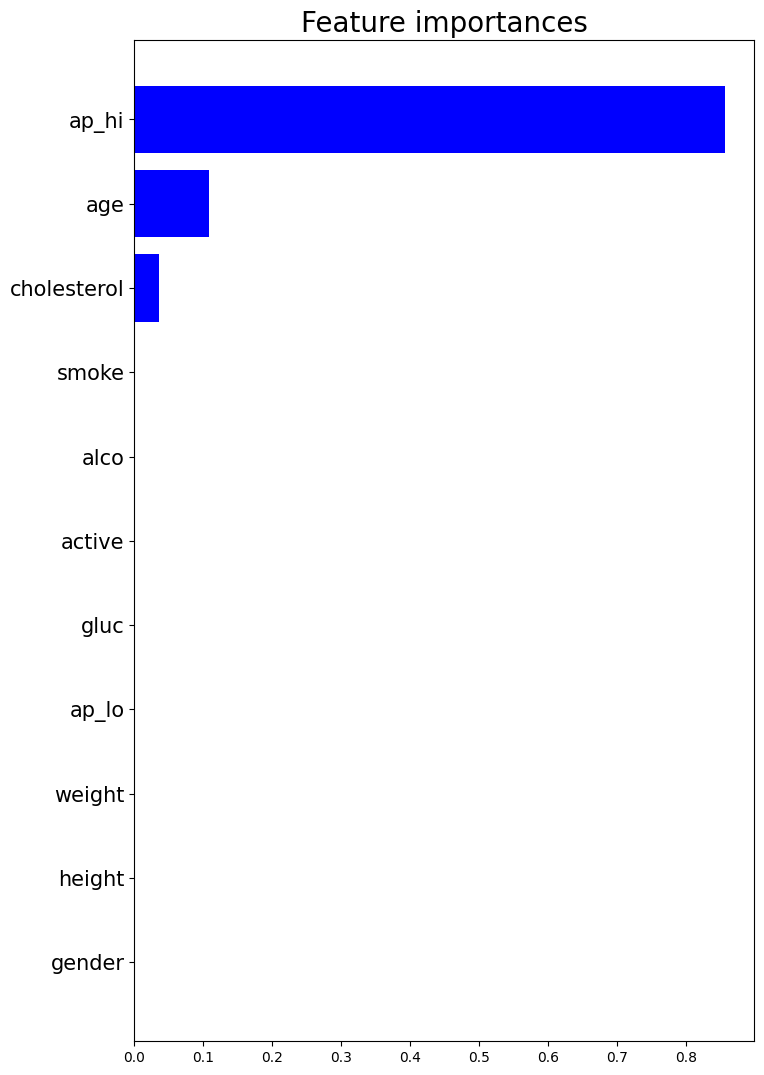

In [ ]:
fn, fi = (
    best_model.feature_names_in_,
    best_model.feature_importances_
)
fn = np.array(fn)[np.argsort(fi)][::-1]
fi = np.sort(fi)[::-1]

plt.figure(figsize=(8, 13))
plt.title(f'Feature importances', fontsize=20);
plt.barh(fn[::-1], fi[::-1], color='blue');
plt.tick_params(axis='y', labelsize=15);

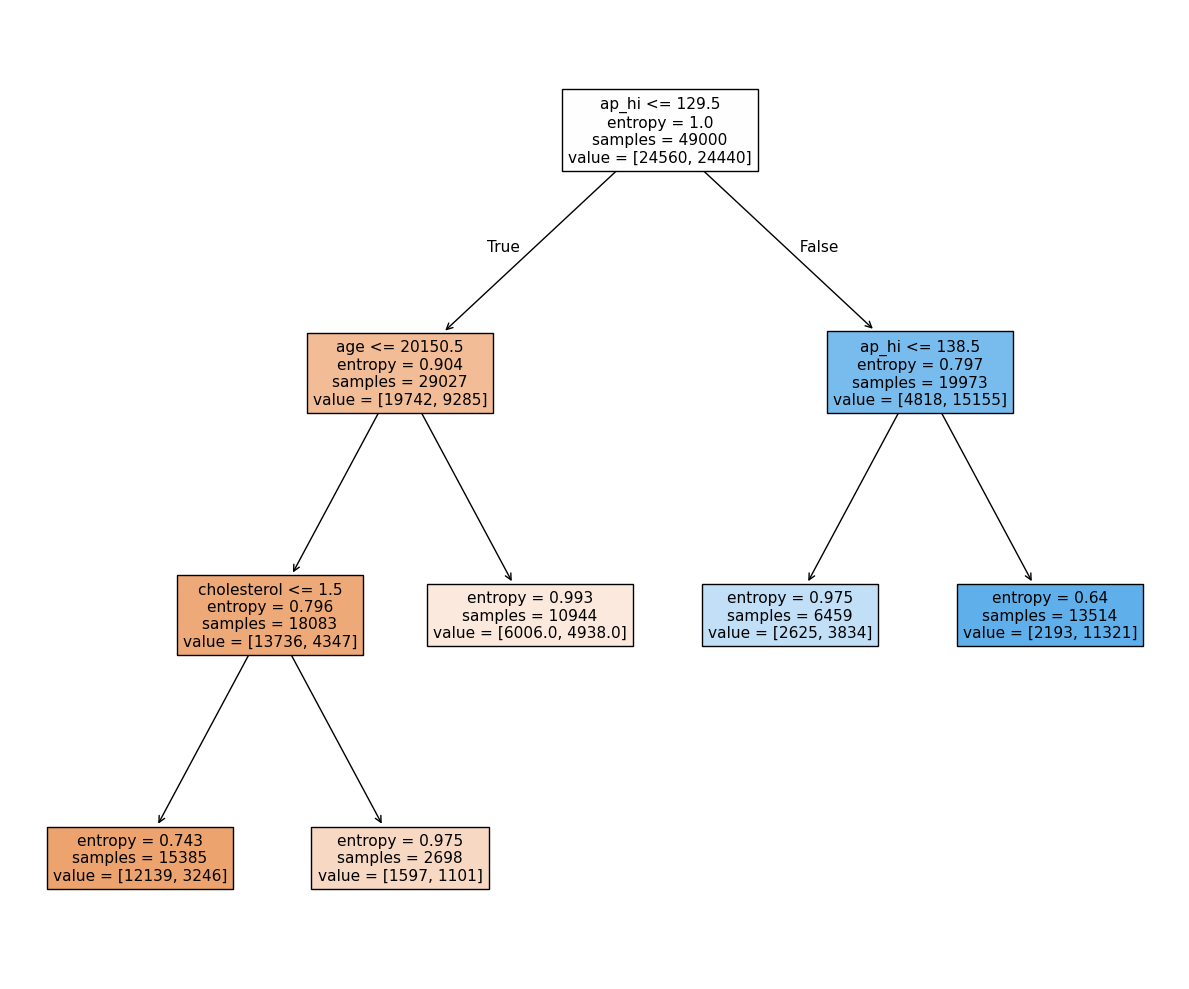

In [ ]:
# only do in case of not deep tree!
# dot_data = StringIO()
# export_graphviz(best_model, out_file=dot_data,
#                 filled=True, rounded=True,
#                 special_characters=True)
# graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
# Image(graph.create_png())
plt.figure(figsize=(12, 10))
plot_tree(best_model, max_depth=3, feature_names=model.feature_names_in_, filled=True, impurity=True, proportion=False)
plt.tight_layout()
plt.show()

<a id='Problem14'></a>
### Problem 14
[back to contents](#home)

Пусть имеется выборка $\{ (x_{i}, y_{i}) \}_{i=1}^{n}, \ x_{i},
 y_{i} \in \mathbb{R}$. Хотим найти коэффициенты $a, b, c$ такие, что Q минимально. Где\\

$$Q = \sum\limits_{i=1}^n \left( f(x_{i}) - y_{i} \right)^2$$

$$
f(x) = \left\{ \begin{array}{cc}
     a, \ x \le c  \\
     b, \ x > c
\end{array}
\right .
$$

Для этого предлагается дополнить следующий код:

```python
import numpy as np
from numpy.typing import NDArray
from math import inf

class DecisionStump:
    def __init__(self):
        """
        f(x) = a*[x <= c] + b*[x > c]
        """
        self.a, self.b, self.c = None, None, None
        
    def fit(self, x: NDArray[float], y: NDArray[float]):
        pass

    def predict(self, x: NDArray[float]) -> NDArray[float]:
        pass
```

In [ ]:
x = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
y = np.array([3, 3, 3, 3, 3, -2, -2, -2, -2, -2])
#a, b, c = 3, -2, 5.5 # c could be any in (5, 6)

# x = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15])
# y = np.array([-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 5, 5, 5, 5, 5])
#a, b, c = -1, 5, 10.5 # could be any in (10, 11)

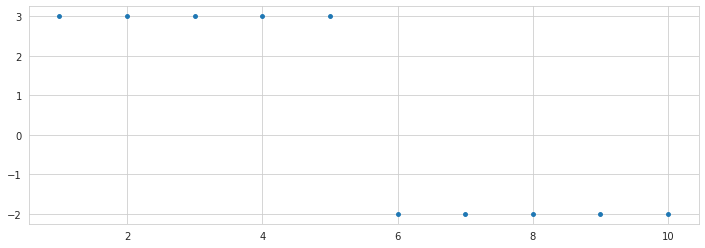

In [ ]:
plt.figure(figsize=(12, 4))
plt.scatter(x, y, s=15);

In [ ]:
import numpy as np
from numpy.typing import NDArray
from math import inf

def mse(y_true: NDArray[float], y_pred: NDArray[float]) -> float:
  return np.mean((y_true - y_pred)**2)

class DecisionStump:
    def __init__(self):
        """
        f(x) = a*[x <= c] + b*[x > c]
        """
        self.a, self.b, self.c = None, None, None

    def fit(self, x: NDArray[float], y: NDArray[float]):
        unq_vals = np.sort(np.unique(x))
        thresholds = (unq_vals[1:] + unq_vals[:-1]) / 2
        best_threshold, best_mse = None, None
        for threshold in thresholds:
          left_pred, right_pred = y[x < threshold].mean(), y[x >= threshold].mean()
          y_pred = left_pred * (x < threshold) + right_pred * (x >= threshold)
          curr_mse = mse(
                y_true=y,
                y_pred=y_pred
            )
          if best_mse is None:
            self.a = left_pred
            self.b = right_pred
            self.c = threshold
            best_mse = curr_mse
            best_threshold = threshold

          if curr_mse < best_mse:
            best_mse = curr_mse
            best_threshold = threshold
            self.a = left_pred
            self.b = right_pred
            self.c = threshold

        return self

    def predict(self, x: NDArray[float]) -> NDArray[float]:
        if self.a is None:
          raise ValueError('train you decision stump first!')

        return self.a * (x < self.c) + self.b * (x >= self.c)


In [ ]:
dc = DecisionStump()
dc.fit(x, y)
print(dc.a, dc.b, dc.c)

3.0 -2.0 5.5


In [ ]:
x_test = np.linspace(x.min(), x.max(), 100)
y_pred = dc.predict(x_test)

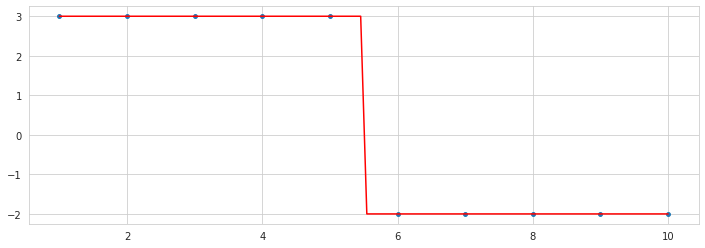

In [ ]:
plt.figure(figsize=(12, 4))
plt.scatter(x, y, s=15)
plt.plot(x_test, y_pred, color='red');